In [ ]:
# Packages and modules
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Pauli
from qiskit_aer import AerSimulator
import numpy as np
import matplotlib.pyplot as plt
from qiskit_ibm_runtime import  EstimatorV2
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit.quantum_info import Clifford, StabilizerState

In [ ]:
"-------------------Floquet evolution operator construction-------------------"
def create_trotter_circuit(num_qubits, Jz, hz, hx, trotter_steps):

    qc = QuantumCircuit(num_qubits)
    for _ in range(trotter_steps):

        for i in range(num_qubits): # Longitudinal Z field
            qc.rz(2 * hz, i)
        for i in range(0, num_qubits - 1, 2):  # Even bonds: ZZ interactions
            qc.rzz(2 * Jz, i, i + 1)
        for i in range(1, num_qubits - 1, 2): # Odd bonds: ZZ interactions
            qc.rzz(2 * Jz, i, i + 1)
        for i in range(num_qubits): # Transverse X kick
            qc.rx(2 * hx, i)

    return qc


"-------------------initial State construction-------------------"
# Domail wall
def domain_wall(num_qubits) -> QuantumCircuit:
    init_qc = QuantumCircuit(num_qubits)
    for i in range(num_qubits//2):
        init_qc.x(i)
    return init_qc

# Nèel(CDW) state
def neel(num_qubits) -> QuantumCircuit:
    init_qc = QuantumCircuit(num_qubits)
    for i in range(num_qubits) :
        if i%2 ==0:
            init_qc.x(i)

    return init_qc


"------------------- Operators -------------------"
def imbalance_operator(num_qubits: int) -> SparsePauliOp:
    pauli_list = []
    for i in range(num_qubits):
        p = ['I'] * num_qubits
        p[i] = 'Z'
        coeff = (-1) ** i
        pauli_list.append(("".join(p), coeff/num_qubits))
    return SparsePauliOp.from_list(pauli_list)


def magnetization(num_qubits) -> list:
    mag_ops = [
        SparsePauliOp.from_sparse_list([("Z", [q], 1.0)], num_qubits=num_qubits)
        for q in range(num_qubits)
    ]

    return mag_ops

In [ ]:
"------------------- backend -------------------"
# Simulator Backend
backend = AerSimulator()
estimator = EstimatorV2(mode = backend)

"------------------- Parameters -------------------"
# total number of sites for floquet evolution
num_qubits = 20

# Coefficients for our XXZ Hamiltonian
Jz = np.pi/2

# field-strength
hx = np.pi/2
hz = np.pi/2

# Time Period
T = 1

# maximum number of trotter steps/floquet repetion
max_ntrot = 50

In [ ]:
"------------------- Constructing Circuit for Simulator/job_submisson -------------------"

initial_circuit = neel(num_qubits)
operator = imbalance_operator(num_qubits)

imbalance_values = []
floquet_periods = []

for m in range(max_ntrot+1):
    if m == 0:
        full_circuit = initial_circuit
    else: 
        evolution_circuit = create_trotter_circuit(num_qubits, Jz*T, hz*T, hx, m)
        full_circuit = initial_circuit.compose(evolution_circuit)

    job = estimator.run([(full_circuit, operator)])
    pub_result = job.result()[0]
    imbalance_values.append(pub_result.data.evs)
    floquet_periods.append(m)


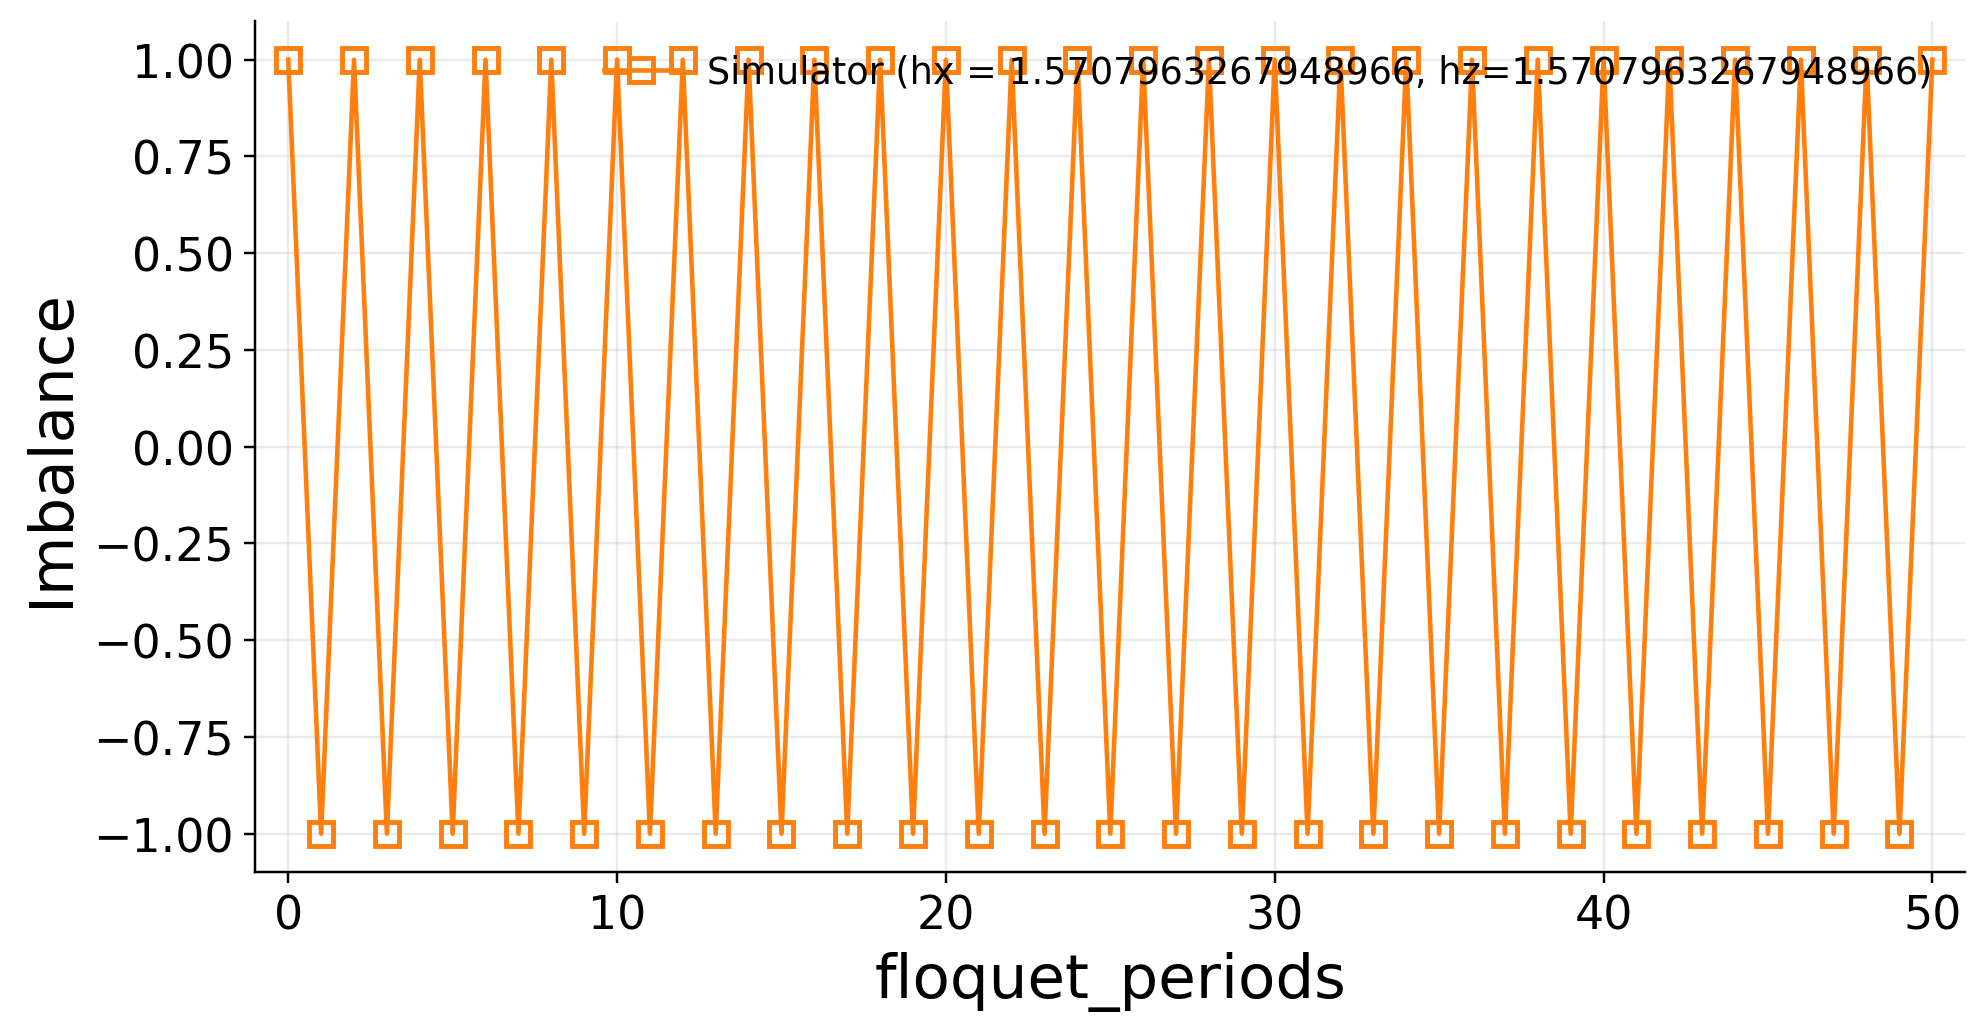

In [5]:
"------------------- Ploting Simulator Results -------------------"
c_sim = "#ff7f0e"  # orange
c_hw  = "#1f77b4"  # blue
c_sim_c  = "#2ca02c"  # green

fig, ax = plt.subplots(figsize=(9, 4.8), dpi=220)

# Simulator (Trotter S=6, h=6) — solid + hollow squares
ax.plot(floquet_periods, imbalance_values,
        linestyle="-", linewidth=1.5,
        marker="s", markersize=8, markerfacecolor="none", markeredgewidth=1.6,
        color=c_sim, label=f"Simulator (hx = {hx}, hz={hz})")


ax.set_xlabel("floquet_periods", fontsize=20)
ax.set_ylabel("Imbalance", fontsize=20)
ax.tick_params(labelsize=15)
ax.grid(alpha=0.25, linewidth=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.margins(x=0.02)
ax.legend(frameon=False, fontsize=12, loc="upper right")

plt.tight_layout()
plt.show()

# Clifford Circuit

In [ ]:
"------------------- Clifford Constructing Circuit for Simulator -------------------"

operator = imbalance_operator(num_qubits)
imbalance_clifford = []

for m in range(max_ntrot + 1):
    qc = neel(num_qubits).compose(create_trotter_circuit(num_qubits, Jz*T, hz*T, hx, m))

    state = StabilizerState(Clifford(qc))
    value = state.expectation_value(operator).real
    imbalance_clifford.append(float(value))

print(imbalance_clifford)


[1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000002, -1.0000000000000002, 1.0000000000000

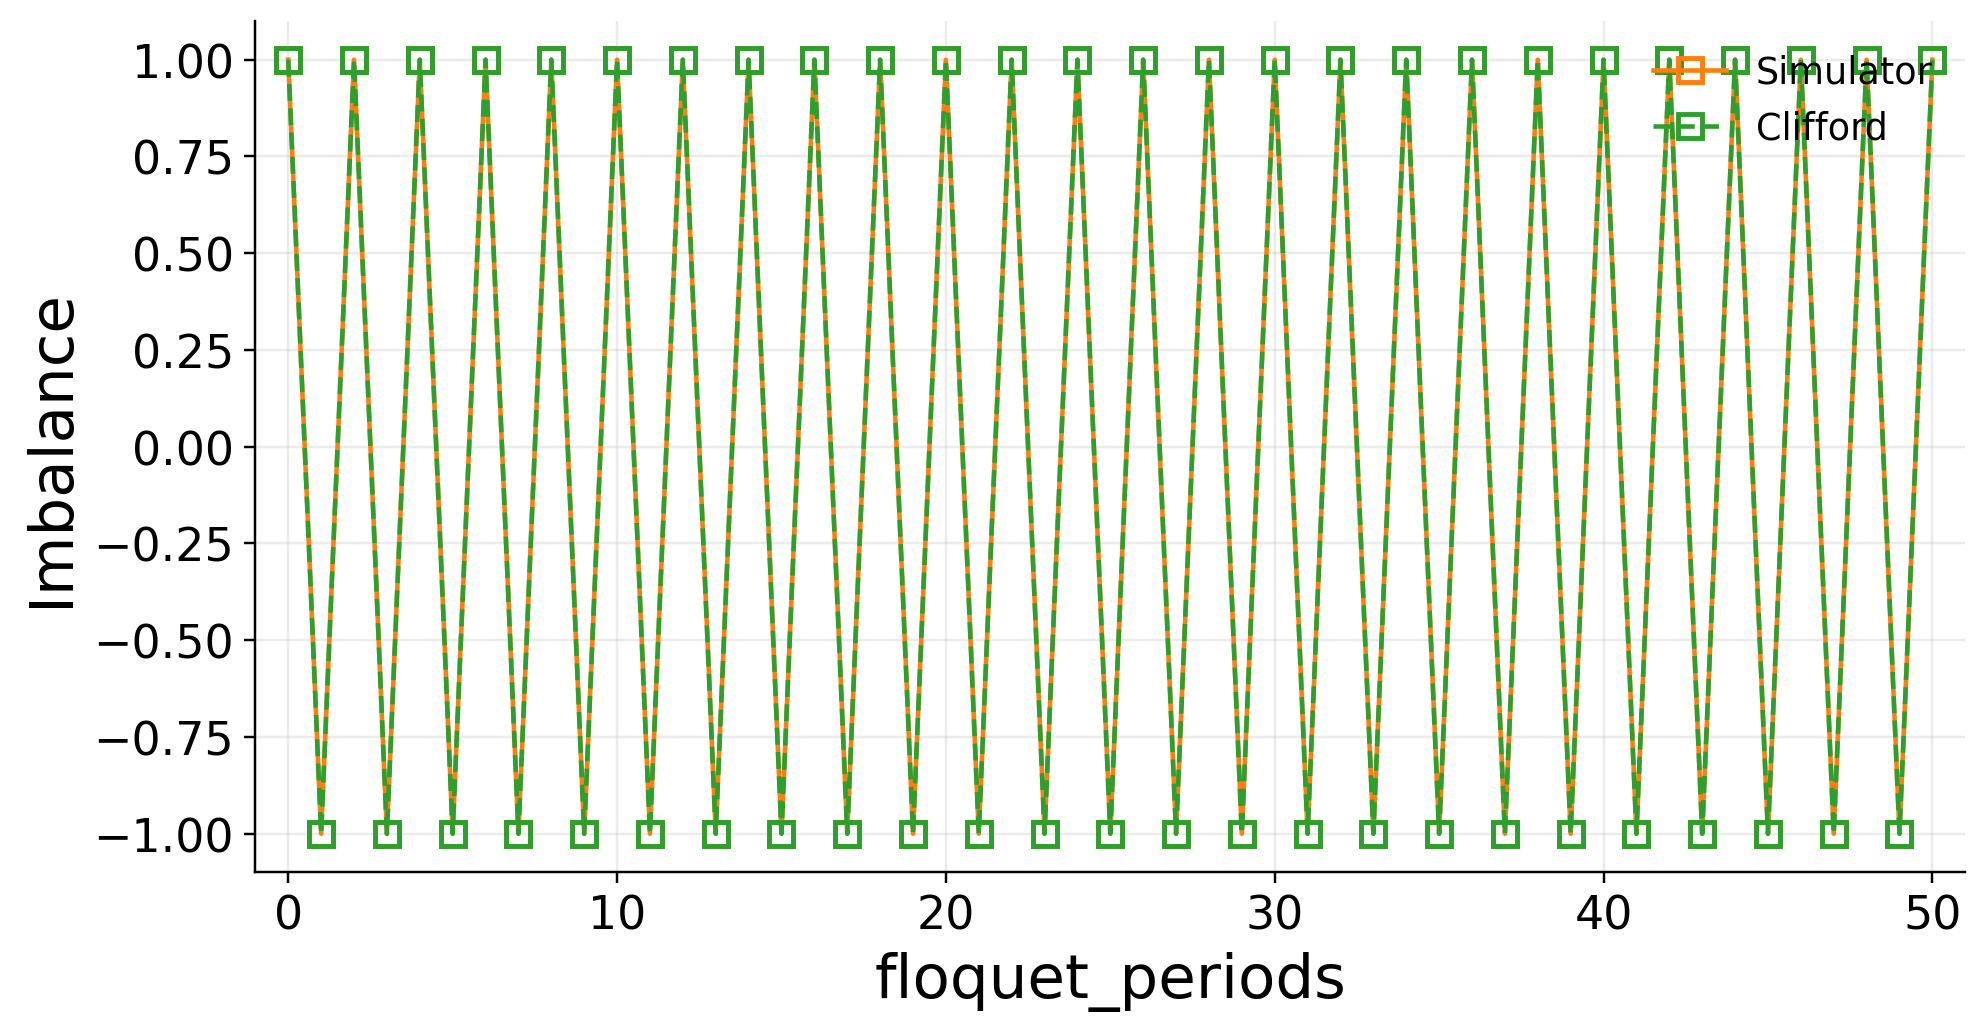

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


c_sim = "#ff7f0e"  # orange
c_hw  = "#1f77b4"  # blue
c_sim_c  = "#2ca02c"  # green

fig, ax = plt.subplots(figsize=(9, 4.8), dpi=220)

# Simulator (Trotter S=6, h=6) — solid + hollow squares
ax.plot(floquet_periods, imbalance_values,
        linestyle="-", linewidth=1.5,
        marker="s", markersize=8, markerfacecolor="none", markeredgewidth=1.6,
        color=c_sim, label=f"Simulator")

ax.plot(floquet_periods, imbalance_clifford,
        linestyle="--", linewidth=1.5,
        marker="s", markersize=8, markerfacecolor="none", markeredgewidth=1.6,
        color=c_sim_c, label=f"Clifford")


ax.set_xlabel("floquet_periods", fontsize=20)
ax.set_ylabel("Imbalance", fontsize=20)
ax.tick_params(labelsize=15)
ax.grid(alpha=0.25, linewidth=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.margins(x=0.02)
ax.legend(frameon=False, fontsize=12, loc="upper right")

plt.tight_layout()
plt.show()
